In [1]:
import numpy as np
import matplotlib.pyplot as plt
x = [1, 2, 3]
y = [2, 4, 6]
w = 0
b = 0
J = []
alpha = 0.1



In [2]:
def FWB(w,b):
    fwb = []
    for i in range(len(x)):
        fwb.append((w*x[i]+b-y[i])**2)

    JWB = (1/(2*3))*(sum(fwb))
    return JWB

In [3]:
def djdw(w,b):
    fwb1 = []
    for k in range(len(x)):
        fwb1.append((w*x[k]+b-y[k])*x[k])
    djdw = (1/3)*(sum(fwb1))
    return djdw

def djdb(w,b):
    fwb = []
    for i in range(len(x)):
        fwb.append(w*x[i]+b-y[i])
    djdb = (1/3)*(sum(fwb))
    return djdb

In [4]:
n = 1000

for i in range(n):
    w1 = djdw(w,b)
    b1 = djdb(w,b)
    J.append(FWB(w,b))
    w = w - alpha * w1
    b = b - alpha * b1
print(w)
print(b)
print(J)


1.9999981835729064
4.129165734264803e-06
[9.333333333333332, 1.8814814814814818, 0.4027621399176958, 0.10876694284407863, 0.04976598147436885, 0.0373901003302839, 0.034277901596684465, 0.03301876767349656, 0.032142506507421724, 0.03135715477657184, 0.03060444696109255, 0.02987247754400553, 0.029158544361681173, 0.028461778781143872, 0.027781683780099736, 0.027117843800821037, 0.026469867017359143, 0.025837373703881717, 0.02521999375099811, 0.02461736600071189, 0.02402913794619842, 0.02345496550796406, 0.022894512829080463, 0.02234745207803374, 0.021813463256825212, 0.021292234013764115, 0.02078345946075487, 0.020286841994955184, 0.019802091124695227, 0.019328923299557592, 0.018867061744517244, 0.018416236298044182, 0.017976183254075594, 0.017546645207763008, 0.017127370904905927, 0.016718115094983235, 0.016318638387696125, 0.015928707112938773, 0.015548093184115708, 0.015176573964724315, 0.014813932138125853, 0.014459955580428233, 0.014114437236406253, 0.013777174998386196, 0.013447971

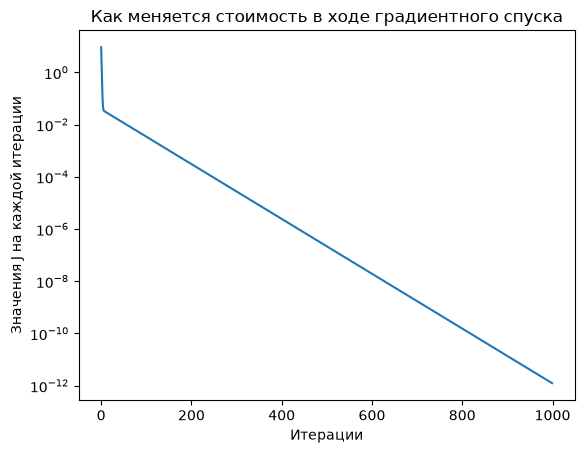

In [5]:
fig, ax = plt.subplots()
ax.plot(range(n), J)
ax.set_title("Как меняется стоимость в ходе градиентного спуска")

ax.set_xlabel("Итерации")

ax.set_ylabel("Значения J на каждой итерации")
ax.set_yscale('log')
plt.show()


In [6]:
k = 50

def grad(alpha, a):
    w = 0
    b = 0
    J1 = []
    for i in range(a):
        w1 = djdw(w,b)
        b1 = djdb(w,b)
        J1.append(FWB(w,b))
        w = w - alpha * w1
        b = b - alpha * b1
    return J1

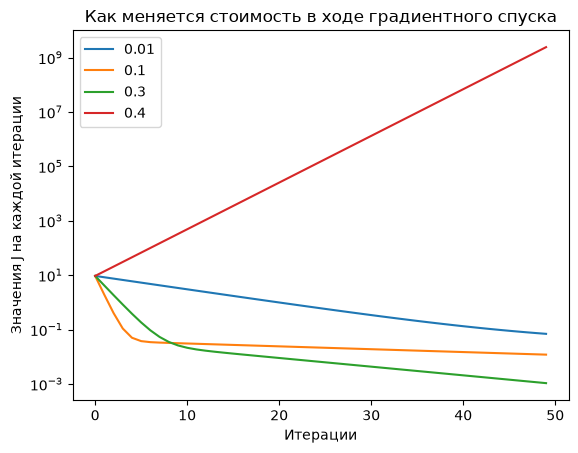

In [7]:
fig, ax = plt.subplots()
ax.plot(range(k), grad(0.01, k), label = '0.01')
ax.plot(range(k), grad(0.1, k), label = '0.1')
ax.plot(range(k), grad(0.3, k), label = '0.3')
ax.plot(range(k), grad(0.4, k), label = '0.4')
ax.legend()
ax.set_title("Как меняется стоимость в ходе градиентного спуска")

ax.set_xlabel("Итерации")

ax.set_ylabel("Значения J на каждой итерации")
ax.set_yscale('log')
plt.show()

## Влияние шага обучения α на градиентный спуск

**Что сделано:**
- одни и те же данные и число итераций (50);
- четыре значения шага α: 0.01, 0.1, 0.3, 0.4;
- шкала по вертикали логарифмическая.

**Для каждого α поведение кривой:**
- При α = 0.1 J падает быстро.
- При α = 0.3 J сначала падает медленнее, но примерно после 8-й итерации обгоняет α = 0.1.
- На коротком участке быстрее α = 0.1, а в долгой перспективе лучше α = 0.3.
- При α = 0.01 J падает очень медленно и к 50-й итерации ещё не дошла до минимума.
- При α = 0.4 J растёт экспоненциально.

**Вывод про малый α:**
- спуск надёжный, но медленный; нужно было взять чуть больший шаг, это не оптимальное значение.

**Вывод про подходящий α:**
- быстрая и устойчивая сходимость.

**Вывод про слишком большой α:**
- шаги перепрыгивают минимум, J растёт, спуск расходится. Это значит, что α нельзя брать как угодно, и по кривой J видно, подходит он или нет.

**Практическое правило:**
- пробовать значения с шагом примерно в 3–10 раз (0.001, 0.01, 0.1…) и брать наибольшее, при котором J убывает стабильно; это делается для подбора оптимального шага;
- кривые с правильно подобранным шагом сначала быстро падают вниз, а потом медленно ползут по пологому склону к минимуму; тут больший шаг ускорил бы процесс.

w := w − α · ∂J/∂w
b := b − α · ∂J/∂b

∂J/∂w = (1/m) · Σ (f(x) − y) · x
∂J/∂b = (1/m) · Σ (f(x) − y)

f(x) = w·x + b

∂J/∂wⱼ = (1/m) · Σ (f(x) − y) · xⱼ